# Setup

In [2]:
# Run once. Safe to skip if everything is already installed. (No tensorflow needed!)
%pip install -q wordcloud nltk scikit-learn pandas matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import json, re, shutil, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import nltk
from IPython.display import display
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

try:
    from wordcloud import WordCloud
except ImportError:
    WordCloud = None
    print("wordcloud not installed - word clouds will be skipped.")

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# ------------------------------------------------------------------ speed settings
N_JOBS = 2             # CPU cores used by GridSearchCV (use -1 for all cores, 1 if the laptop struggles)
SAMPLE_LIMIT = None    # e.g. 20000 -> use at most 20 000 rows per dataset for a quick test run
INCLUDE_KNN = True     # KNN is the slowest model to predict; set False to skip it
MODEL_DIR = Path("models2")
CACHE_DIR = Path("tfidf_cache2")

for pkg in ("stopwords", "wordnet"):
    nltk.download(pkg, quiet=True)

STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()

REDDIT_LABELS = ["Not Depression", "Depression"]   # is_depression: 0 / 1
TWITTER_LABELS = ["Negative", "Positive"]          # sentiment:     0 / 1


def find_file(name):
    """Locate a dataset file in the usual places."""
    for folder in [".", "data", "/content", "/content/drive/MyDrive", "/mnt/user-data/uploads"]:
        path = Path(folder) / name
        if path.exists():
            return path
    raise FileNotFoundError(f"'{name}' not found. Put it next to this notebook (or in a 'data' folder).")


def preprocess_twitter(text):
    """lower-case -> keep letters only -> drop stop-words -> lemmatise."""
    text = re.sub(r"[^a-z\s]", "", str(text).lower())
    return " ".join(LEMMATIZER.lemmatize(t) for t in text.split() if t not in STOP_WORDS)


def normalize_reddit(text):
    """Mimics how `clean_text` in the Reddit file was produced (letters only, lemmatised,
    stop-words kept). Used for NEW text at prediction time; the CSV is already clean."""
    text = re.sub(r"[^a-z]+", " ", str(text).lower())
    return " ".join(LEMMATIZER.lemmatize(t) for t in text.split())

In [4]:
# ------------------------------------------------------------------ shared helpers
RESULTS = []       # one row per trained model -> comparison table
CANDIDATES = []    # everything needed to save a model later


def evaluate(dataset, name, y_true, y_pred, labels, seconds):
    """Print the report, draw confusion matrix + metric bars, store the result."""
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, pos_label=1, average="binary", zero_division=0)
    print(f"[{dataset}] {name}: accuracy={acc:.4f}  precision={prec:.4f}  recall={rec:.4f}  "
          f"f1={f1:.4f}  (train time {seconds:.1f}s)\n")
    print(classification_report(y_true, y_pred, target_names=labels, zero_division=0))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=labels).plot(
        cmap="Blues", ax=axes[0], colorbar=False)
    axes[0].set_title(f"{name} - confusion matrix")
    names, vals = ["Accuracy", "Precision", "Recall", "F1-score"], [acc, prec, rec, f1]
    axes[1].bar(names, vals, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
    axes[1].set_ylim(0, 1.1)
    axes[1].set_title(f"{name} - metrics (positive class = '{labels[1]}')")
    for i, v in enumerate(vals):
        axes[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
    plt.tight_layout()
    plt.show()

    metrics = {"accuracy": float(acc), "precision": float(prec), "recall": float(rec), "f1": float(f1)}
    RESULTS.append({"dataset": dataset, "model": name, **metrics, "train_seconds": round(seconds, 1)})
    return metrics


def show_samples(proba_fn, examples, true_labels, labels, prep):
    """Predict hand-written examples with the model's OWN predict function."""
    proba = np.asarray(proba_fn([prep(t) for t in examples])).ravel()
    pred = (proba >= 0.5).astype(int)
    display(pd.DataFrame({
        "text": [t if len(t) <= 80 else t[:77] + "..." for t in examples],
        "actual": [labels[i] for i in true_labels],
        "predicted": [labels[i] for i in pred],
        f"P({labels[1]})": proba.round(3),
        "correct": [bool(a == b) for a, b in zip(true_labels, pred)],
    }))


def make_pipe(clf):
    """TF-IDF + classifier. `memory` caches the fitted TF-IDF so grid search does not recompute it."""
    return Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))), ("clf", clf)],
                    memory=str(CACHE_DIR))


def run_model(dataset, name, clf, param_grid, splits, labels, prep_name, prep, examples, true_labels):
    """(Optional) grid-search with 3-fold CV -> evaluate on the untouched test set -> register."""
    X_tr, X_te, y_tr, y_te = splits
    print(f"\n===== {dataset.upper()} - {name} =====")
    start = time.time()
    pipe = make_pipe(clf)
    if param_grid:
        search = GridSearchCV(pipe, param_grid, cv=3, scoring="accuracy", n_jobs=N_JOBS)
        search.fit(X_tr, y_tr)
        best = search.best_estimator_
        print(f"Best params: {search.best_params_}   (CV accuracy {search.best_score_:.4f})")
    else:
        best = pipe.fit(X_tr, y_tr)
    best.set_params(memory=None)                       # keep the saved pipeline free of cache paths
    seconds = time.time() - start

    metrics = evaluate(dataset, name, y_te, best.predict(X_te), labels, seconds)
    proba_fn = lambda texts: best.predict_proba(texts)[:, 1]
    CANDIDATES.append(dict(dataset=dataset, model=name, obj=best, metrics=metrics,
                           labels=labels, preprocess=prep_name))
    show_samples(proba_fn, examples, true_labels, labels, prep)
    return best


def model_zoo():
    """name -> (classifier, parameter grid). Grids are small on purpose (fast on a laptop)."""
    zoo = {
        "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                          {"clf__max_depth": [20, None], "clf__min_samples_leaf": [5, 10]}),
        "ANN": (MLPClassifier(activation="relu", solver="adam", alpha=1e-3, batch_size=64, max_iter=30,
                              early_stopping=True, validation_fraction=0.1, n_iter_no_change=3,
                              random_state=SEED),
                {"clf__hidden_layer_sizes": [(64,), (128, 64)]}),
    }
    if INCLUDE_KNN:
        zoo["KNN"] = (KNeighborsClassifier(metric="cosine", algorithm="brute"),
                      {"clf__n_neighbors": [5, 11], "clf__weights": ["uniform", "distance"]})
    return zoo


def plot_ann_curve(pipe, title):
    """Learning curve of the ANN: training loss and validation accuracy per epoch."""
    ann = pipe.named_steps["clf"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].plot(ann.loss_curve_); ax[0].set_title(f"{title} - training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(ann.validation_scores_); ax[1].set_title(f"{title} - validation accuracy"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

# Dataset Analysis

In [5]:
reddit_df = pd.read_csv(find_file("depression_dataset_reddit_cleaned.csv")).dropna(subset=["clean_text", "is_depression"])
reddit_df["clean_text"] = reddit_df["clean_text"].astype(str)
reddit_df["is_depression"] = reddit_df["is_depression"].astype(int)

twitter_df = pd.read_csv(find_file("Twitter-Dataset-Trimmed.csv")).dropna(subset=["text", "sentiment"])
twitter_df["sentiment"] = twitter_df["sentiment"].astype(int)

if SAMPLE_LIMIT:   # optional speed-up for quick test runs
    reddit_df = reddit_df.sample(min(SAMPLE_LIMIT, len(reddit_df)), random_state=SEED)
    twitter_df = twitter_df.sample(min(SAMPLE_LIMIT, len(twitter_df)), random_state=SEED)

twitter_df["processed_text"] = twitter_df["text"].astype(str).apply(preprocess_twitter)

assert set(reddit_df["is_depression"].unique()) <= {0, 1}, "is_depression must be 0/1"
assert set(twitter_df["sentiment"].unique()) <= {0, 1}, "sentiment must be 0 (negative) / 1 (positive)"

# Posts that become empty after cleaning carry no signal
twitter_df = twitter_df[twitter_df["processed_text"].str.strip() != ""]

print("Reddit :", reddit_df.shape, "| Twitter:", twitter_df.shape)
display(reddit_df[["clean_text", "is_depression"]].head(3))
display(twitter_df[["text", "processed_text", "sentiment"]].head(3))

Reddit : (7731, 2) | Twitter: (39993, 3)


,clean_text,is_depression
0,we understand that most people who reply immed...,1
1,welcome to r depression s check in post a plac...,1
2,anyone else instead of sleeping more when depr...,1


,text,processed_text,sentiment
0,@xnausikaax oh no! where did u order from? tha...,xnausikaax oh u order thats horrible,0
1,A great hard training weekend is over. a coup...,great hard training weekend couple day rest le...,0
2,"Right, off to work Only 5 hours to go until I...",right work hour go im free xd,0


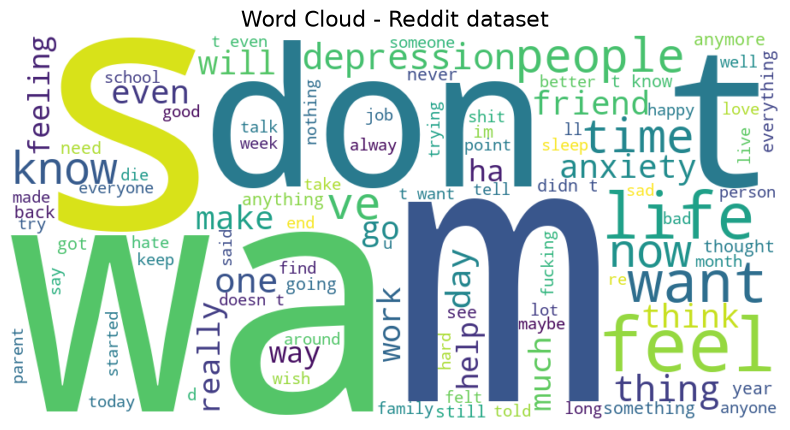

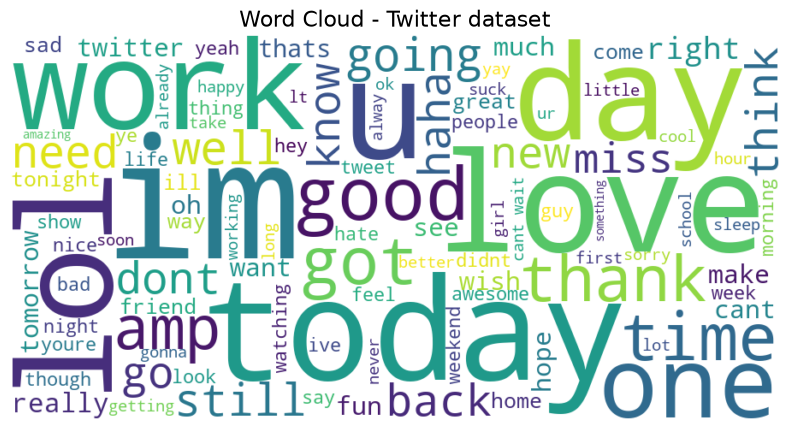

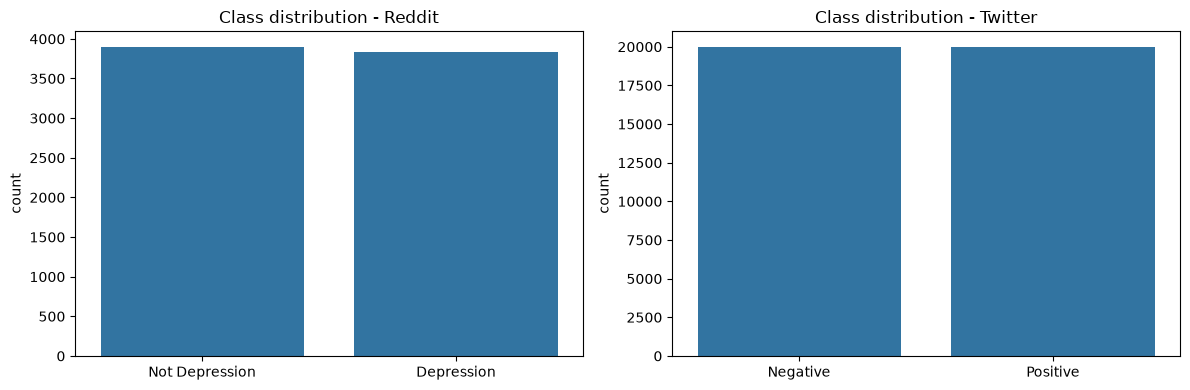

In [6]:
def plot_word_cloud(texts, title, max_words=100):
    if WordCloud is None:
        print("(wordcloud not installed - skipped)")
        return
    wc = WordCloud(max_words=max_words, background_color="white", width=900, height=450).generate(" ".join(texts))
    plt.figure(figsize=(10, 5)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
    plt.title(title, fontsize=16); plt.show()

plot_word_cloud(reddit_df["clean_text"], "Word Cloud - Reddit dataset")
plot_word_cloud(twitter_df["processed_text"], "Word Cloud - Twitter dataset")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, df, col, labels, title in [
        (axes[0], reddit_df, "is_depression", REDDIT_LABELS, "Class distribution - Reddit"),
        (axes[1], twitter_df, "sentiment", TWITTER_LABELS, "Class distribution - Twitter")]:
    sns.countplot(x=col, data=df, order=[0, 1], ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(labels); ax.set_xlabel(""); ax.set_title(title)
plt.tight_layout(); plt.show()

In [7]:
# ONE stratified 80/20 split per dataset, shared by all models -> fair comparison
reddit_splits = train_test_split(reddit_df["clean_text"], reddit_df["is_depression"],
                                 test_size=0.2, random_state=SEED, stratify=reddit_df["is_depression"])
twitter_splits = train_test_split(twitter_df["processed_text"], twitter_df["sentiment"],
                                  test_size=0.2, random_state=SEED, stratify=twitter_df["sentiment"])

REDDIT_EXAMPLES = [
    "is annoyed with the amount of glass on dublin road and the number of puncture i am getting",
    "my friend coco chris had a party this weekend and it seemed to have been awesome fail i wasnae there",
    "for about a week now i ve been experiencing extreme anxiety and panic restlessness a need to move my leg etc it s been waking me up in the middle of the night and i fear i m either crazy or i m dying",
    "geoffmartinez youre going to be in mexico on easter why",
    "rsk depression",
]
REDDIT_TRUE = [0, 0, 1, 0, 1]

TWITTER_EXAMPLES = [
    "I absolutely love this, best day ever!",
    "This is the worst service I have ever had, so disappointed.",
    "Can't wait for the weekend, heading to the beach with my friends.",
    "My phone broke again and I'm so annoyed.",
    "Just got promoted at work, feeling great!",
]
TWITTER_TRUE = [1, 0, 1, 0, 1]   # 1 = positive sentiment, 0 = negative sentiment

# Reddit dataset - Depression vs Not Depression


===== REDDIT - Decision Tree =====
Best params: {'clf__max_depth': 20, 'clf__min_samples_leaf': 5}   (CV accuracy 0.9360)
[reddit] Decision Tree: accuracy=0.9425  precision=0.9593  recall=0.9231  f1=0.9409  (train time 27.3s)

                precision    recall  f1-score   support

Not Depression       0.93      0.96      0.94       780
    Depression       0.96      0.92      0.94       767

      accuracy                           0.94      1547
     macro avg       0.94      0.94      0.94      1547
  weighted avg       0.94      0.94      0.94      1547



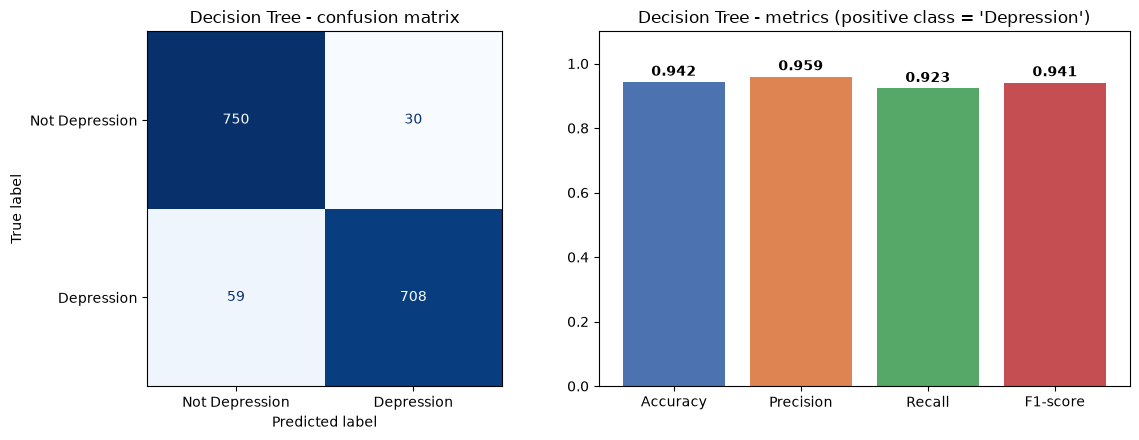

,text,actual,predicted,P(Depression),correct
0,is annoyed with the amount of glass on dublin ...,Not Depression,Not Depression,0.000,True
1,my friend coco chris had a party this weekend ...,Not Depression,Not Depression,0.025,True
2,for about a week now i ve been experiencing ex...,Depression,Depression,1.000,True
3,geoffmartinez youre going to be in mexico on e...,Not Depression,Not Depression,0.027,True
4,rsk depression,Depression,Depression,1.000,True



===== REDDIT - ANN =====
Best params: {'clf__hidden_layer_sizes': (128, 64)}   (CV accuracy 0.9460)
[reddit] ANN: accuracy=0.9509  precision=0.9564  recall=0.9439  f1=0.9501  (train time 125.6s)

                precision    recall  f1-score   support

Not Depression       0.95      0.96      0.95       780
    Depression       0.96      0.94      0.95       767

      accuracy                           0.95      1547
     macro avg       0.95      0.95      0.95      1547
  weighted avg       0.95      0.95      0.95      1547



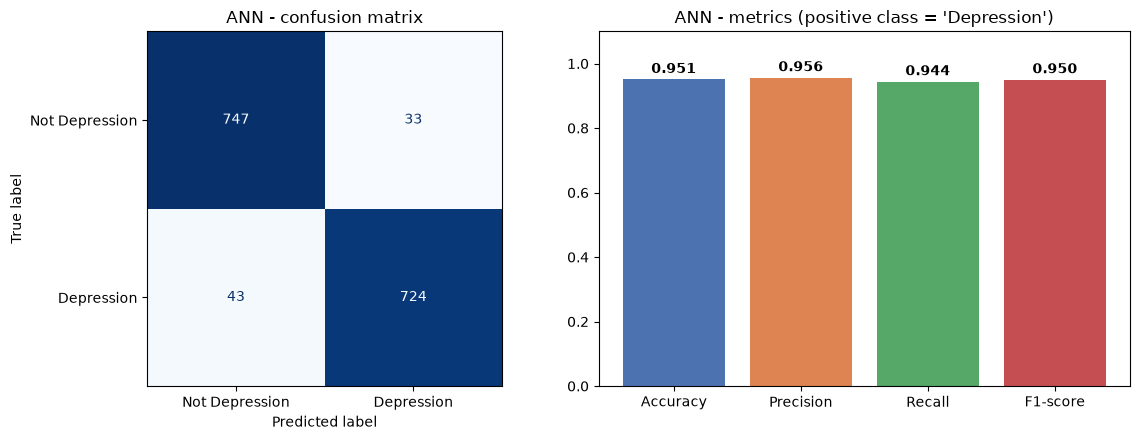

,text,actual,predicted,P(Depression),correct
0,is annoyed with the amount of glass on dublin ...,Not Depression,Not Depression,0.032,True
1,my friend coco chris had a party this weekend ...,Not Depression,Not Depression,0.009,True
2,for about a week now i ve been experiencing ex...,Depression,Depression,0.965,True
3,geoffmartinez youre going to be in mexico on e...,Not Depression,Not Depression,0.005,True
4,rsk depression,Depression,Depression,0.996,True



===== REDDIT - KNN =====
Best params: {'clf__n_neighbors': 11, 'clf__weights': 'distance'}   (CV accuracy 0.9208)
[reddit] KNN: accuracy=0.9282  precision=0.9469  recall=0.9061  f1=0.9260  (train time 12.7s)

                precision    recall  f1-score   support

Not Depression       0.91      0.95      0.93       780
    Depression       0.95      0.91      0.93       767

      accuracy                           0.93      1547
     macro avg       0.93      0.93      0.93      1547
  weighted avg       0.93      0.93      0.93      1547



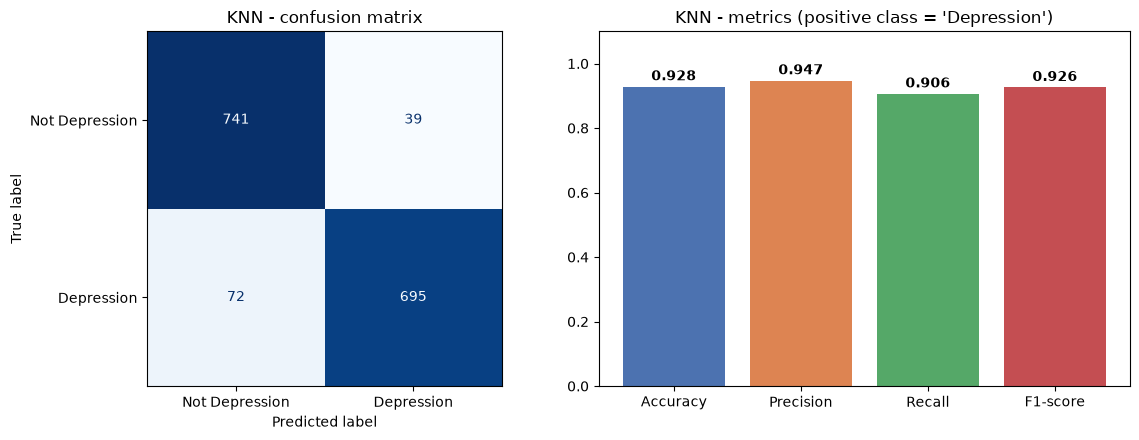

,text,actual,predicted,P(Depression),correct
0,is annoyed with the amount of glass on dublin ...,Not Depression,Not Depression,0.000,True
1,my friend coco chris had a party this weekend ...,Not Depression,Not Depression,0.000,True
2,for about a week now i ve been experiencing ex...,Depression,Not Depression,0.481,False
3,geoffmartinez youre going to be in mexico on e...,Not Depression,Not Depression,0.000,True
4,rsk depression,Depression,Depression,1.000,True


In [8]:
reddit_models = {}
for name, (clf, grid) in model_zoo().items():
    reddit_models[name] = run_model("reddit", name, clf, grid, reddit_splits, REDDIT_LABELS,
                                    "reddit", normalize_reddit, REDDIT_EXAMPLES, REDDIT_TRUE)

## Interpretability - Reddit

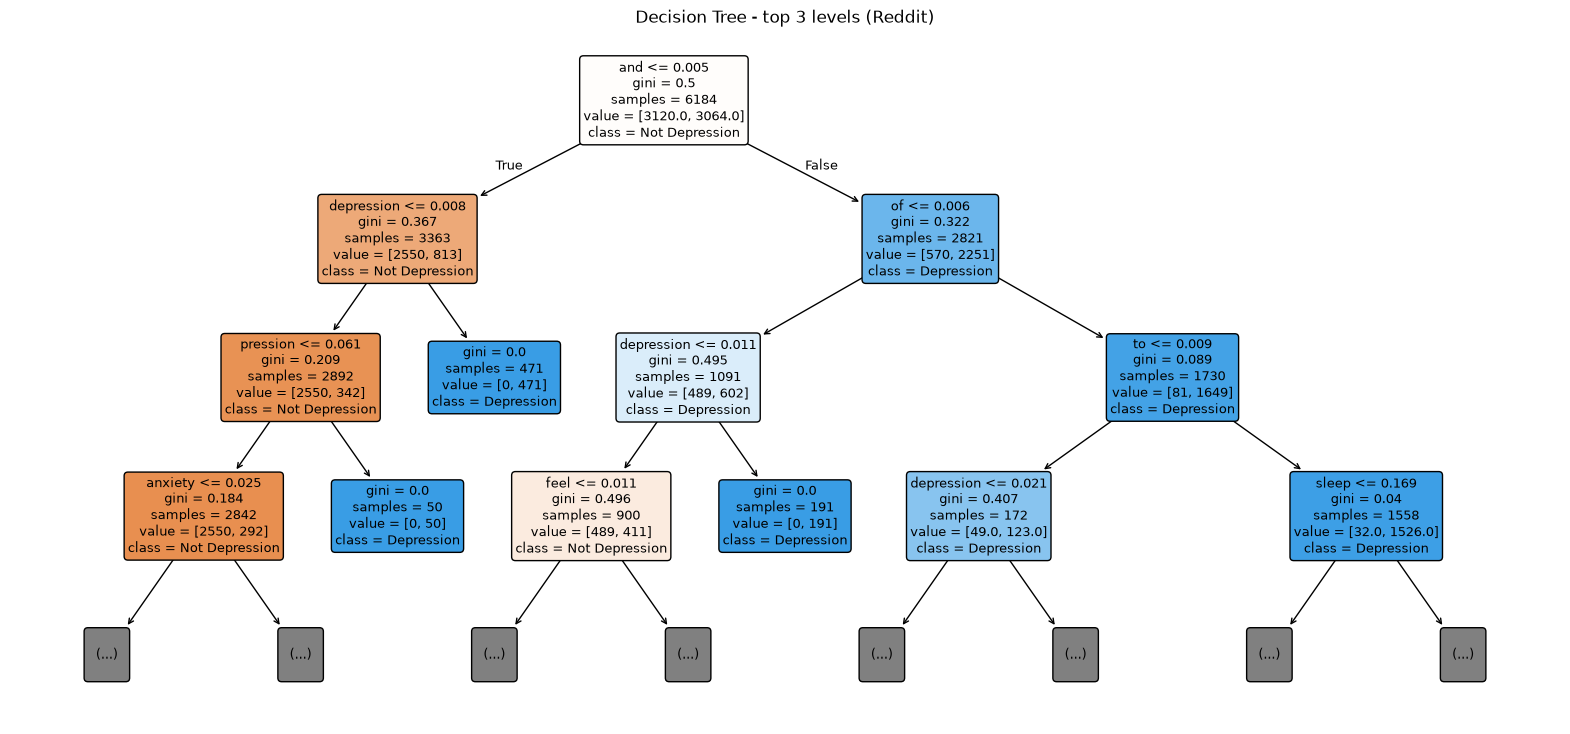

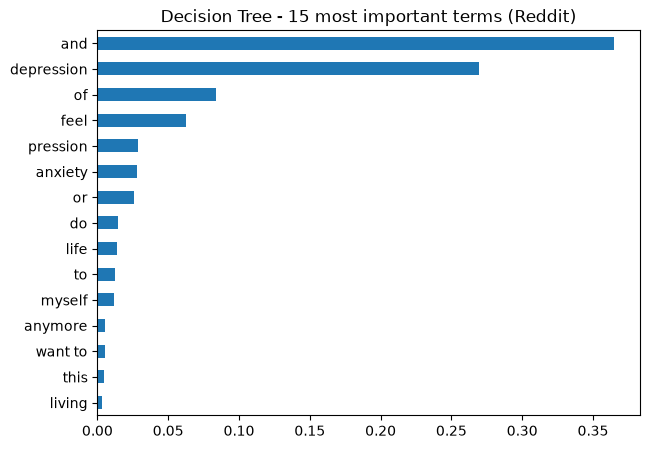

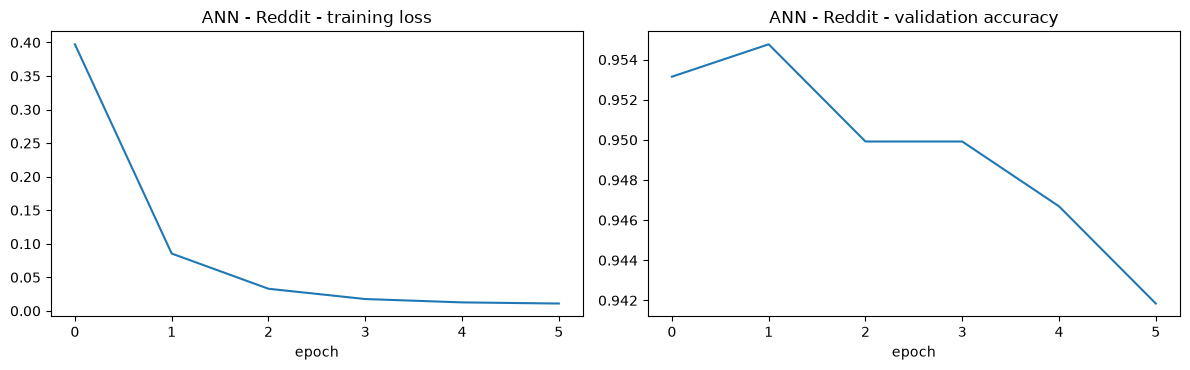

In [9]:
# Decision tree: top of the tree + most important words
tfidf_fit, tree = reddit_models["Decision Tree"].named_steps["tfidf"], reddit_models["Decision Tree"].named_steps["clf"]
features = tfidf_fit.get_feature_names_out()
plt.figure(figsize=(20, 9))
plot_tree(tree, max_depth=3, feature_names=features, class_names=REDDIT_LABELS, filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree - top 3 levels (Reddit)"); plt.show()

top = pd.Series(tree.feature_importances_, index=features).nlargest(15)[::-1]
top.plot.barh(figsize=(7, 5), title="Decision Tree - 15 most important terms (Reddit)"); plt.show()

plot_ann_curve(reddit_models["ANN"], "ANN - Reddit")

# Twitter dataset - Positive vs Negative sentiment


===== TWITTER - Decision Tree =====
Best params: {'clf__max_depth': None, 'clf__min_samples_leaf': 10}   (CV accuracy 0.6784)
[twitter] Decision Tree: accuracy=0.6935  precision=0.6904  recall=0.7017  f1=0.6960  (train time 49.4s)

              precision    recall  f1-score   support

    Negative       0.70      0.69      0.69      3999
    Positive       0.69      0.70      0.70      4000

    accuracy                           0.69      7999
   macro avg       0.69      0.69      0.69      7999
weighted avg       0.69      0.69      0.69      7999



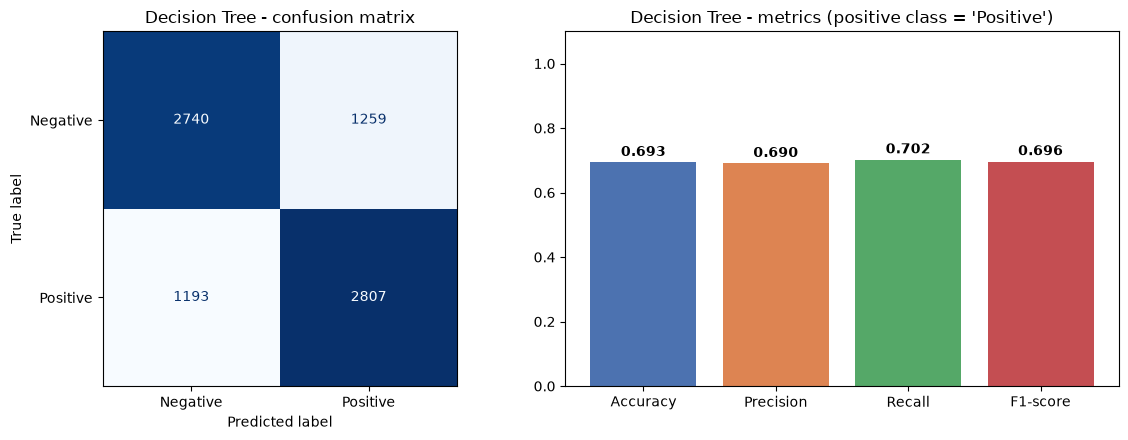

,text,actual,predicted,P(Positive),correct
0,"I absolutely love this, best day ever!",Positive,Positive,0.727,True
1,"This is the worst service I have ever had, so ...",Negative,Negative,0.000,True
2,"Can't wait for the weekend, heading to the bea...",Positive,Positive,0.929,True
3,My phone broke again and I'm so annoyed.,Negative,Negative,0.000,True
4,"Just got promoted at work, feeling great!",Positive,Positive,0.750,True



===== TWITTER - ANN =====
Best params: {'clf__hidden_layer_sizes': (64,)}   (CV accuracy 0.7440)
[twitter] ANN: accuracy=0.7548  precision=0.7429  recall=0.7795  f1=0.7608  (train time 571.6s)

              precision    recall  f1-score   support

    Negative       0.77      0.73      0.75      3999
    Positive       0.74      0.78      0.76      4000

    accuracy                           0.75      7999
   macro avg       0.76      0.75      0.75      7999
weighted avg       0.76      0.75      0.75      7999



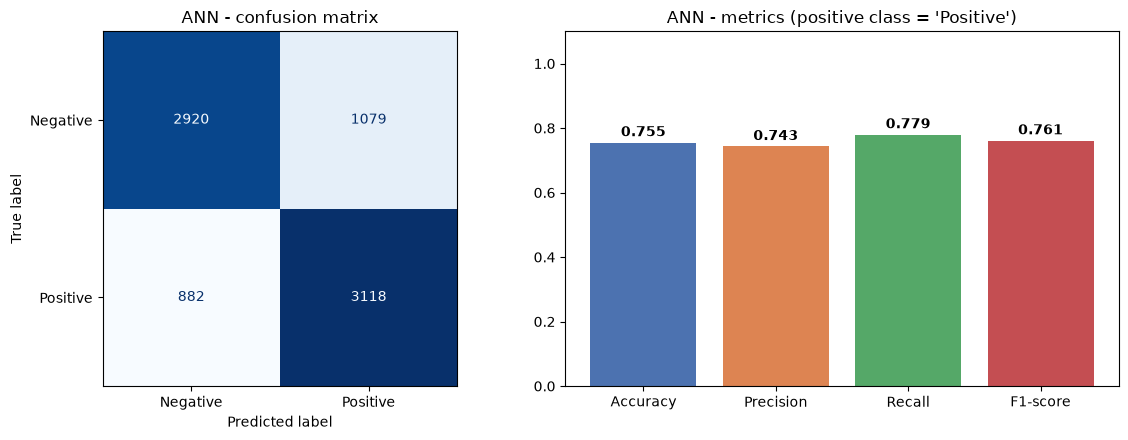

,text,actual,predicted,P(Positive),correct
0,"I absolutely love this, best day ever!",Positive,Positive,0.839,True
1,"This is the worst service I have ever had, so ...",Negative,Negative,0.100,True
2,"Can't wait for the weekend, heading to the bea...",Positive,Positive,0.848,True
3,My phone broke again and I'm so annoyed.,Negative,Negative,0.054,True
4,"Just got promoted at work, feeling great!",Positive,Negative,0.375,False



===== TWITTER - KNN =====
Best params: {'clf__n_neighbors': 11, 'clf__weights': 'uniform'}   (CV accuracy 0.6925)
[twitter] KNN: accuracy=0.7028  precision=0.6915  recall=0.7325  f1=0.7114  (train time 47.4s)

              precision    recall  f1-score   support

    Negative       0.72      0.67      0.69      3999
    Positive       0.69      0.73      0.71      4000

    accuracy                           0.70      7999
   macro avg       0.70      0.70      0.70      7999
weighted avg       0.70      0.70      0.70      7999



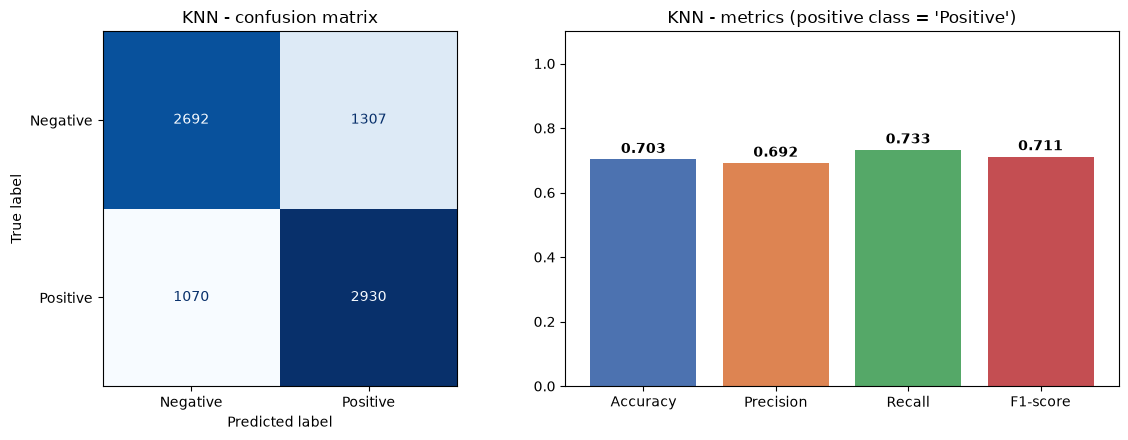

,text,actual,predicted,P(Positive),correct
0,"I absolutely love this, best day ever!",Positive,Positive,0.545,True
1,"This is the worst service I have ever had, so ...",Negative,Negative,0.091,True
2,"Can't wait for the weekend, heading to the bea...",Positive,Positive,0.909,True
3,My phone broke again and I'm so annoyed.,Negative,Negative,0.182,True
4,"Just got promoted at work, feeling great!",Positive,Positive,0.545,True


In [10]:
twitter_models = {}
for name, (clf, grid) in model_zoo().items():
    twitter_models[name] = run_model("twitter", name, clf, grid, twitter_splits, TWITTER_LABELS,
                                     "twitter", preprocess_twitter, TWITTER_EXAMPLES, TWITTER_TRUE)

## Interpretability - Twitter

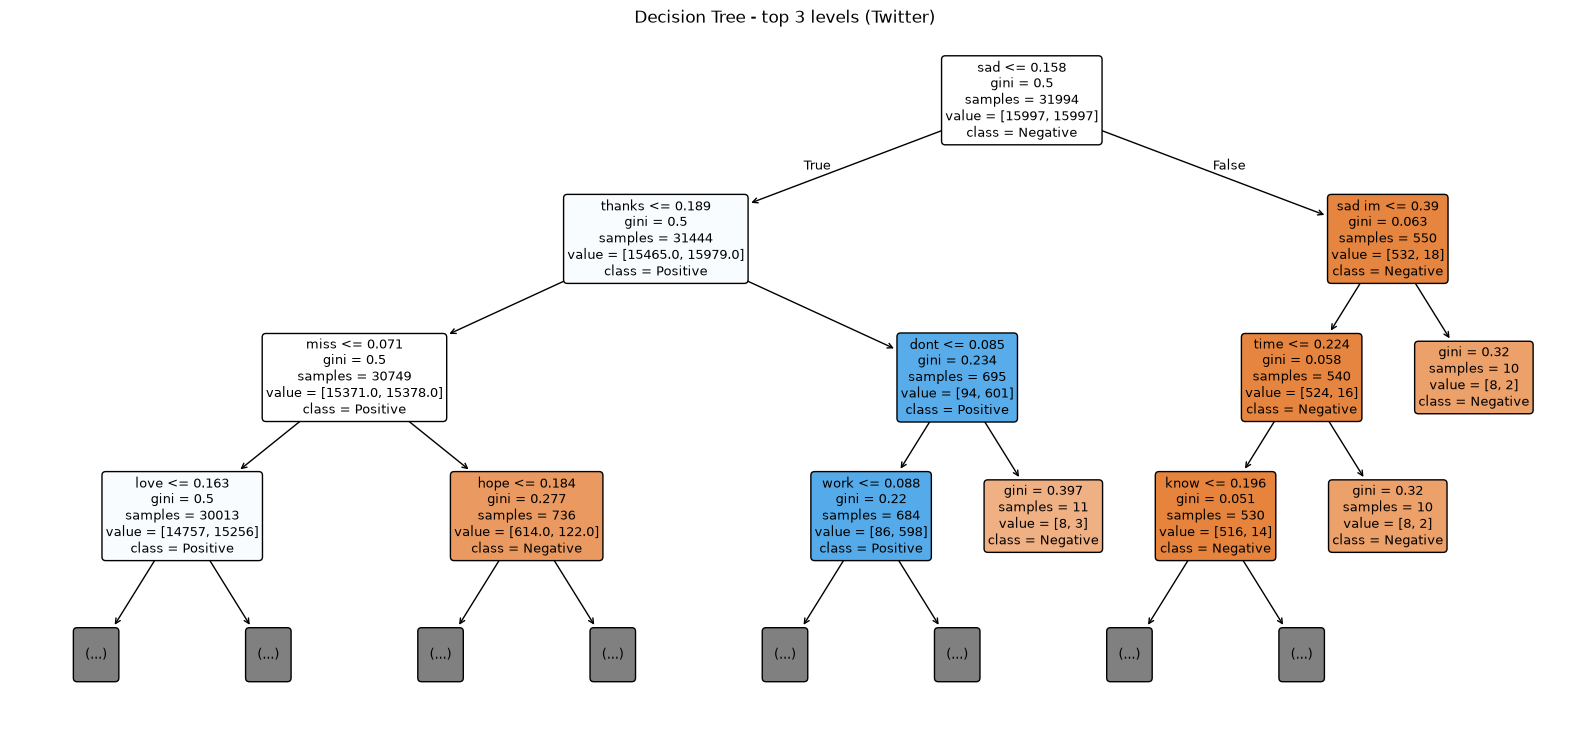

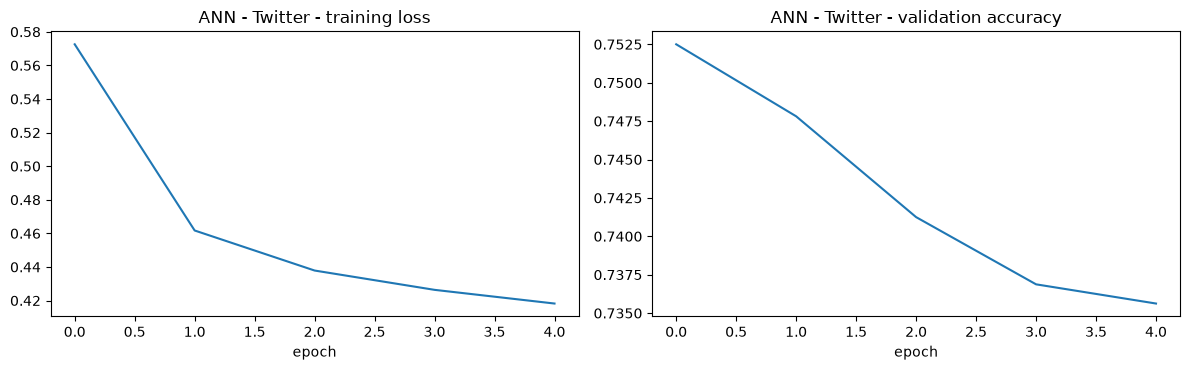

In [11]:
tfidf_fit, tree = twitter_models["Decision Tree"].named_steps["tfidf"], twitter_models["Decision Tree"].named_steps["clf"]
features = tfidf_fit.get_feature_names_out()
plt.figure(figsize=(20, 9))
plot_tree(tree, max_depth=3, feature_names=features, class_names=TWITTER_LABELS, filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree - top 3 levels (Twitter)"); plt.show()

plot_ann_curve(twitter_models["ANN"], "ANN - Twitter")

# Model comparison

,dataset,model,accuracy,precision,recall,f1,train_seconds
0,reddit,ANN,0.9509,0.9564,0.9439,0.9501,125.6
1,reddit,Decision Tree,0.9425,0.9593,0.9231,0.9409,27.3
2,reddit,KNN,0.9282,0.9469,0.9061,0.9260,12.7
3,twitter,ANN,0.7548,0.7429,0.7795,0.7608,571.6
4,twitter,KNN,0.7028,0.6915,0.7325,0.7114,47.4
5,twitter,Decision Tree,0.6935,0.6904,0.7018,0.6960,49.4


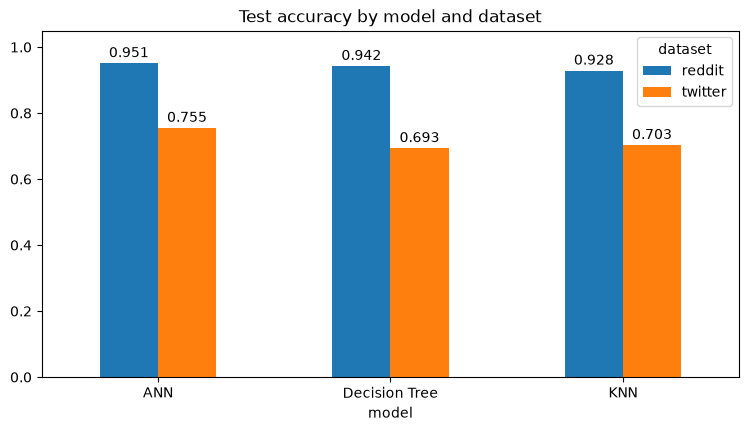

In [12]:
results_df = pd.DataFrame(RESULTS)
display(results_df.sort_values(["dataset", "accuracy"], ascending=[True, False]).round(4).reset_index(drop=True))

pivot = results_df.pivot(index="model", columns="dataset", values="accuracy")
ax = pivot.plot.bar(figsize=(9, 4.5), rot=0, ylim=(0, 1.05), title="Test accuracy by model and dataset")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=2)
plt.show()

In [13]:
# Auto-generated summary (always matches the numbers above)
for ds, grp in results_df.groupby("dataset"):
    best_row = grp.sort_values(["accuracy", "f1"], ascending=False).iloc[0]
    worst_row = grp.sort_values("accuracy").iloc[0]
    print(f"{ds.capitalize():8s} best : {best_row['model']:20s} accuracy={best_row['accuracy']:.4f}  recall={best_row['recall']:.4f}")
    print(f"{'':8s} worst: {worst_row['model']:20s} accuracy={worst_row['accuracy']:.4f}  recall={worst_row['recall']:.4f}")

Reddit   best : ANN                  accuracy=0.9509  recall=0.9439
         worst: KNN                  accuracy=0.9282  recall=0.9061
Twitter  best : ANN                  accuracy=0.7548  recall=0.7795
         worst: Decision Tree        accuracy=0.6935  recall=0.7017


# Detailed analysis

The exact numbers are in the comparison table above (regenerated on every run, so no scores are hard-coded here).

**How to read the results**

- **Reddit** posts are long, topic-specific and already cleaned, so the ANN usually separates *Depression* from *Not Depression* best; the Decision Tree relies on a handful of strong terms (see the importance plot) and KNN depends on cosine similarity between whole posts.
- **Twitter** texts are short, noisy and labelled by *sentiment*, not depression, so scores are lower across the board. KNN suffers most from sparse, short texts.
- **Accuracy is not enough.** In mental-health screening a missed case (false negative) is more costly than a false alarm, so compare the **recall** column too. The Streamlit app exposes the decision threshold for this reason.
- **Speed.** The `train_seconds` column shows the cost of each model: the Decision Tree is quickest, the ANN takes longer to train, and KNN is the slowest to predict.

**Limitations**

- Public social-media data of limited size and unknown labelling quality; models can inherit bias and may not generalise to other platforms, languages or groups.
- The best model is *selected* on the same test set it is scored on; for a publication use a separate final hold-out set.

# Save the best model for each dataset

The best model (highest test accuracy, ties broken by F1 - change `SELECT_BY` to `"recall"` / `"f1"` if you prefer) is saved to `models2/<dataset>/`:

```
models2/
|-- results.csv                 # comparison table (shown in the app)
|-- reddit/   meta.json + model.joblib   (TF-IDF + classifier pipeline)
`-- twitter/  meta.json + model.joblib
```

In [14]:
SELECT_BY = "accuracy"      # "accuracy" | "f1" | "recall" | "precision"

if MODEL_DIR.exists():
    shutil.rmtree(MODEL_DIR)            # avoid stale files from an older run
MODEL_DIR.mkdir(parents=True)

for dataset in ["reddit", "twitter"]:
    pool = [c for c in CANDIDATES if c["dataset"] == dataset]
    best = max(pool, key=lambda c: (c["metrics"][SELECT_BY], c["metrics"]["f1"]))
    out = MODEL_DIR / dataset
    out.mkdir()

    joblib.dump(best["obj"], out / "model.joblib")        # full pipeline: TF-IDF + classifier
    meta = {
        "dataset": dataset,
        "model_name": best["model"],
        "model_type": "sklearn",
        "labels": best["labels"],              # index 0 / 1
        "preprocess": best["preprocess"],      # "reddit" or "twitter" (must match app2UI.py)
        "selected_by": SELECT_BY,
        "metrics": best["metrics"],
        "files": {"model": "model.joblib"},
    }
    (out / "meta.json").write_text(json.dumps(meta, indent=2))
    print(f"{dataset:8s} -> {best['model']:20s} ({SELECT_BY}={best['metrics'][SELECT_BY]:.4f})  saved to {out}/")

results_df.round(4).to_csv(MODEL_DIR / "results.csv", index=False)
shutil.rmtree(CACHE_DIR, ignore_errors=True)   # remove the TF-IDF cache

reddit   -> ANN                  (accuracy=0.9509)  saved to models2\reddit/
twitter  -> ANN                  (accuracy=0.7548)  saved to models2\twitter/


## Verify the saved models (reload from disk, exactly like `app2UI.py` does)

In [15]:
def load_saved(dataset):
    d = MODEL_DIR / dataset
    meta = json.loads((d / "meta.json").read_text())
    pipe = joblib.load(d / meta["files"]["model"])
    return meta, (lambda texts: pipe.predict_proba(texts)[:, 1])

for dataset, examples, true, prep in [("reddit", REDDIT_EXAMPLES, REDDIT_TRUE, normalize_reddit),
                                      ("twitter", TWITTER_EXAMPLES, TWITTER_TRUE, preprocess_twitter)]:
    meta, fn = load_saved(dataset)
    print(f"--- reloaded {dataset} model: {meta['model_name']}")
    show_samples(fn, examples, true, meta["labels"], prep)

--- reloaded reddit model: ANN


,text,actual,predicted,P(Depression),correct
0,is annoyed with the amount of glass on dublin ...,Not Depression,Not Depression,0.032,True
1,my friend coco chris had a party this weekend ...,Not Depression,Not Depression,0.009,True
2,for about a week now i ve been experiencing ex...,Depression,Depression,0.965,True
3,geoffmartinez youre going to be in mexico on e...,Not Depression,Not Depression,0.005,True
4,rsk depression,Depression,Depression,0.996,True


--- reloaded twitter model: ANN


,text,actual,predicted,P(Positive),correct
0,"I absolutely love this, best day ever!",Positive,Positive,0.839,True
1,"This is the worst service I have ever had, so ...",Negative,Negative,0.100,True
2,"Can't wait for the weekend, heading to the bea...",Positive,Positive,0.848,True
3,My phone broke again and I'm so annoyed.,Negative,Negative,0.054,True
4,"Just got promoted at work, feeling great!",Positive,Negative,0.375,False


# Conclusion & next step

The highest-scoring model per dataset was saved automatically. Launch the web interface with:

```bash
pip install streamlit scikit-learn nltk pandas joblib
streamlit run app2UI.py
```

Remember: this is a screening *aid* for research and education - not a medical diagnosis.